In [37]:
import pandas as pd
import seaborn as sns

In [2]:
sales = pd.read_csv("C:/Users/GUPTA/Downloads/retail_sales_dataset.csv")

In [3]:
sales.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
sales.shape

(1000, 9)

## 1.Check Columns datatype and null values

In [5]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [6]:
# Chaning the data type of date 
sales["Date"] = pd.to_datetime(sales["Date"])

In [7]:
# mean, median, mode, standard deviation for all numerical columns
sales.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


## 2. Creating a line chart

In [8]:
sales.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


### Observation – Quaterly Sales Trend

The quarterly sales trend shows how total sales changed over time. 
The chart helps identify quarterly with higher and lower sales activity. 

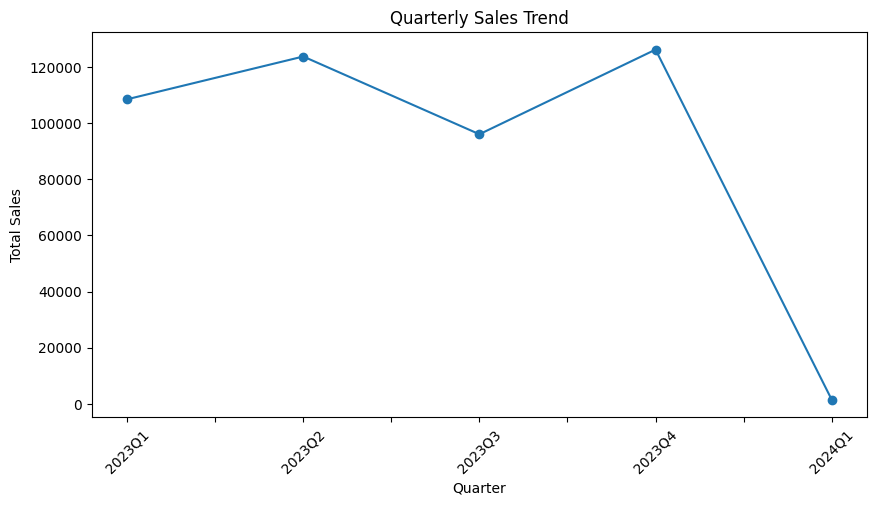

In [9]:
# Quarterly sales trend
import matplotlib.pyplot as plt

Quarterly_sales = sales.groupby(
    sales["Date"].dt.to_period("Q")
)["Total Amount"].sum()

Quarterly_sales.index = Quarterly_sales.index.astype(str)

sales_trend = Quarterly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

sales_trend.set_title("Quarterly Sales Trend")
sales_trend.set_xlabel("Quarter")
sales_trend.set_ylabel("Total Sales")

plt.xticks(rotation=45)
plt.show()

## ### Observation – Monthly Sales Trend

The monthly sales trend shows how total sales changed over time.
The chart helps identify months with higher and lower sales activity.

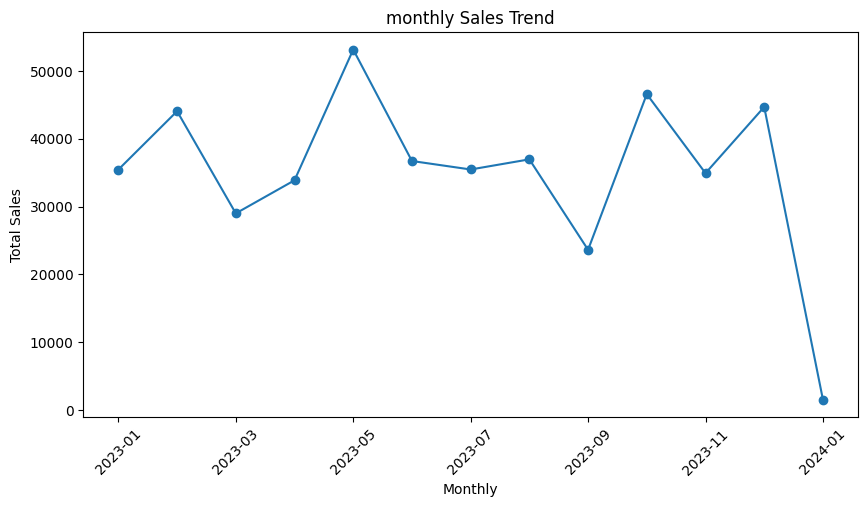

In [10]:
# Monthly Sales Trend
monthly_sales = sales.groupby(
    sales["Date"].dt.to_period("M")
)["Total Amount"].sum()

monthly_sales.index = monthly_sales.index.astype(str)

sales_trend = monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

sales_trend.set_title("monthly Sales Trend")
sales_trend.set_xlabel("Monthly")
sales_trend.set_ylabel("Total Sales")

plt.xticks(rotation=45)
plt.show() 

## 3. Customer demographics analysis

In [11]:
sales.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [12]:
sales["Age"].unique()

array([34, 26, 50, 37, 30, 45, 46, 63, 52, 23, 35, 22, 64, 42, 19, 27, 47,
       62, 18, 49, 28, 38, 43, 39, 44, 51, 58, 48, 55, 20, 40, 54, 36, 31,
       21, 57, 25, 56, 29, 61, 32, 41, 59, 60, 33, 53, 24])

In [15]:
# Creating a Age Bucket
sales["Age Group"] = pd.cut(
    sales["Age"],
    bins=[0,25,35,45,55,100],
    labels=["18-25","26-35","36-45","46-55","56+"]
)

In [16]:
age_distribution = sales["Age Group"].value_counts().sort_index()
print(age_distribution)

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56+      195
Name: count, dtype: int64


## Observation – Customer Age Group Distribution
The age-group distribution shows the demographic composition of the customer base.
The 46–55 age group represents a significant portion of customers,
while the older age groups account for a smaller share of the customer base.

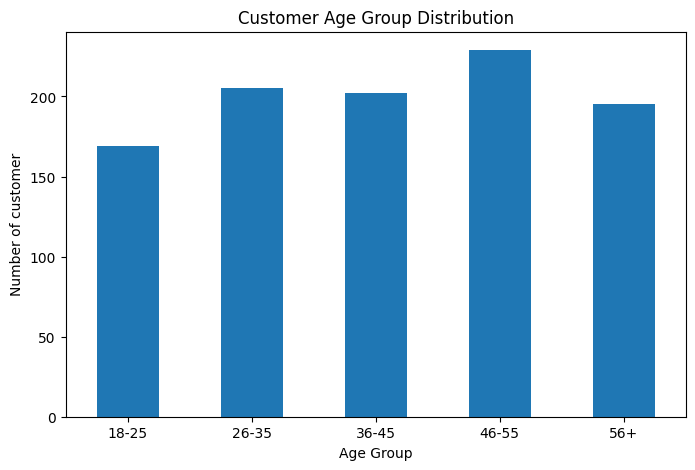

In [21]:
age_distribution.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Customer Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Number of customer")
plt.xticks(rotation=0)
plt.show()

In [24]:
sales.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,26-35
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,26-35
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,46-55
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,36-45
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,26-35


In [28]:
sales["Product Category"].unique()

<StringArray>
['Beauty', 'Clothing', 'Electronics']
Length: 3, dtype: str

In [29]:
top_product = sales.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False).head(3)

print(top_product)

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


### Observation – Top 3 Best-Selling Products

The chart identifies the products with the highest number of units sold. A small number of products account for a significant portion of total unit sales, highlighting the importance of these products for overall sales volume and inventory planning.

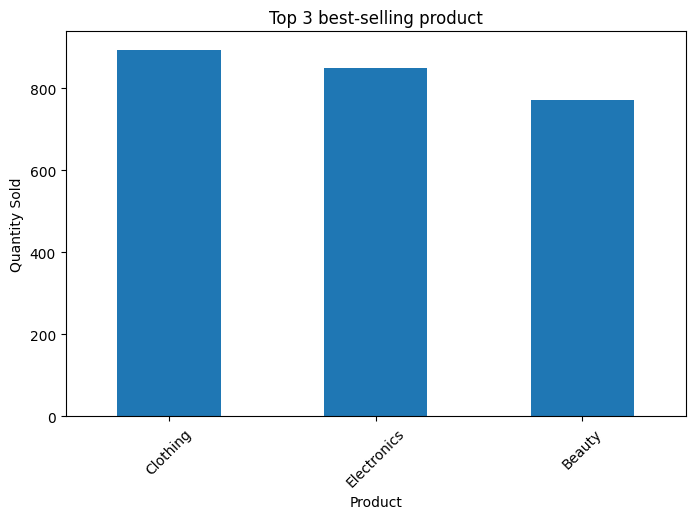

In [33]:
top_product.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Top 3 best-selling product")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.show()

In [34]:
# Slecating Numerical columns
numerical_data = sales.select_dtypes(include="number")

print(numerical_data.columns)

Index(['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount'], dtype='str')


In [36]:
# Caluculate correlation matrix
correlation_matrix = numerical_data.corr()
print(correlation_matrix)

                Transaction ID       Age  Quantity  Price per Unit  \
Transaction ID        1.000000  0.065191 -0.026623       -0.060837   
Age                   0.065191  1.000000 -0.023737       -0.038423   
Quantity             -0.026623 -0.023737  1.000000        0.017501   
Price per Unit       -0.060837 -0.038423  0.017501        1.000000   
Total Amount         -0.075034 -0.060568  0.373707        0.851925   

                Total Amount  
Transaction ID     -0.075034  
Age                -0.060568  
Quantity            0.373707  
Price per Unit      0.851925  
Total Amount        1.000000  


### Observation – Correlation Analysis

The correlation matrix shows the relationships between the numerical variables in the dataset. Total Amount has a positive relationship with Quantity and Price per Unit, which is expected because changes in these variables can directly influence transaction value. Variables with correlation values close to zero show little linear relationship.

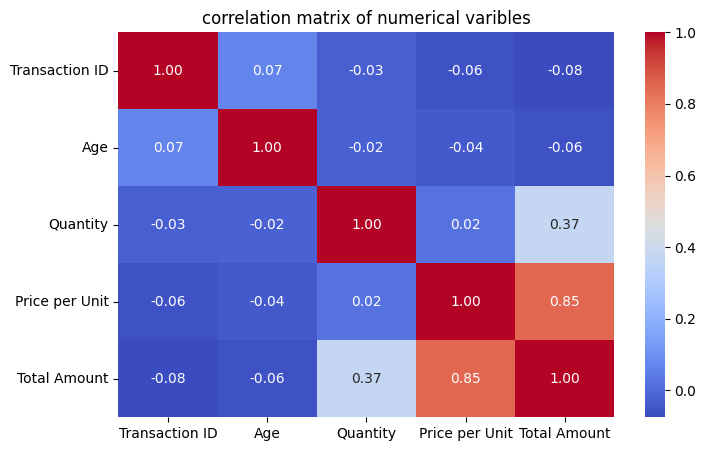

In [38]:
plt.figure(figsize=(8,5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("correlation matrix of numerical varibles")
plt.show()

In [39]:
sales.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,26-35
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,26-35
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,46-55
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,36-45
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,26-35


In [40]:
# calculate a sales by age group and gender

age_gender_sales = sales.groupby(
    ["Age Group", "Gender"],
    observed=True
)["Total Amount"].sum().unstack()

print(age_gender_sales)

Gender     Female   Male
Age Group               
18-25       39470  45080
26-35       55115  43365
36-45       46735  45135
46-55       53310  47380
56+         38210  42200


### Observation – Average Sales Value by Age Group

The visualization compares the average transaction value across different customer age groups. This provides an additional perspective beyond customer counts, helping identify which age groups tend to generate higher-value purchases. A group with fewer customers may still be commercially important if its average transaction value is relatively high.

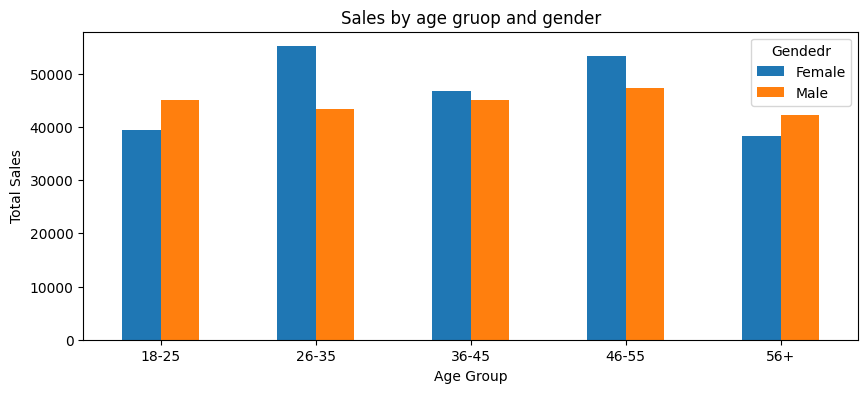

In [41]:
age_gender_sales.plot(
    kind="bar",
    figsize=(10,4)
)

plt.title("Sales by age gruop and gender")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.legend(title="Gendedr")
plt.show()

# This char shows sales by age and gender

#  Conclusion and Business Recommendations

## Conclusion

The sales data analysis provides insight into sales trends, customer demographics, product performance, and relationship between numerical varibales.
Monthly and Quarterly sales helps evaluate the sales performance, while customer demographic analysis highlight the composition of customer base.
Product analysis identifies the best-product and catogery generating the most revenue. 

## Business Recommendations

1. Use Sales Trends for Better Planning.

   Monthly and quarterly sales trends should be monitored regularly to identify periods of strong or weak performance

2. Monitor Revenue and Customer Purchasing Patterns

   The business should track total revenue, quantity sold, and average transaction value together.
   Correlation analysis can help identify relationships    between numerical variables, while average
   transaction value by age group can reveal potentially valuable customer segments

3. Optimize Inventory for Best-Selling Products.

   The business should prioritize inventory replenishment for the top 3 best-selling products to reduce stockouts and maintain product availability. Sales quantities should be reviewed monthly to identify consistently high-demand products and avoid overstocking slow-moving items.